# Figure 8-5 — ngspice compared with the analytical model

The ideal deck is a high-gain voltage-controlled source plus explicit offset
and bias-current sources, so it solves the same linear network as the nodal
model. A second trace uses the OPA365 macromodel when a local copy is
available. That file is not in this repository. The macromodel result is
reported on its own and is not adjusted to match the ideal curve.

The passband transient is a 250 kHz sine, 1 V peak, with no offset. The run
is 100 µs and the fit uses the last 40 µs.

Created with Grok Build.


In [1]:
import sys

import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg", force=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import io
from pathlib import Path
from IPython.display import display, Image

def _show(*args, **kwargs):
    buf = io.BytesIO()
    fig = plt.gcf()
    fig.savefig(buf, format="png", dpi=150, bbox_inches="tight")
    plt.close("all")
    display(Image(data=buf.getvalue()))

plt.show = _show

def _find_project_root():
    start = Path.cwd().resolve()
    named = Path("Sections/Electronics/Analog_and_Digital/OPA365_Fig85")
    candidates = [start, *start.parents, start / named]
    if start.name == "notebooks":
        candidates.insert(0, start.parent)
    for cand in candidates:
        if (cand / "mfb_design" / "__init__.py").is_file():
            return cand
    raise FileNotFoundError("mfb_design package was not found")

ROOT = _find_project_root()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))


In [2]:
from mfb_design.params import CircuitParams, ToleranceSpec

p = CircuitParams(
    R1=549.0,
    R2=1.24e3,
    R3=549.0,
    C1=1.0e-9,
    C2=150.0e-12,
    r_tol=ToleranceSpec(0.001),
    c_tol=ToleranceSpec(0.01),
)
SPICE_WORKERS = 4
N_MC_AC = 2000
N_MC_TRAN = 500
MC_SEED = 42
print(
    f"R1={p.R1:g} ohm  R2={p.R2:g} ohm  R3={p.R3:g} ohm  "
    f"C1={p.C1:g} F  C2={p.C2:g} F"
)
print(
    f"supplies {p.op.v_pos:g} V / {p.op.v_neg:g} V, "
    f"tone {p.op.f_passband_hz:g} Hz, {p.op.v_in_peak:g} V peak"
)
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)


R1=549 ohm  R2=1240 ohm  R3=549 ohm  C1=1e-09 F  C2=1.5e-10 F
supplies 2.5 V / -2.5 V, tone 250000 Hz, 1 V peak


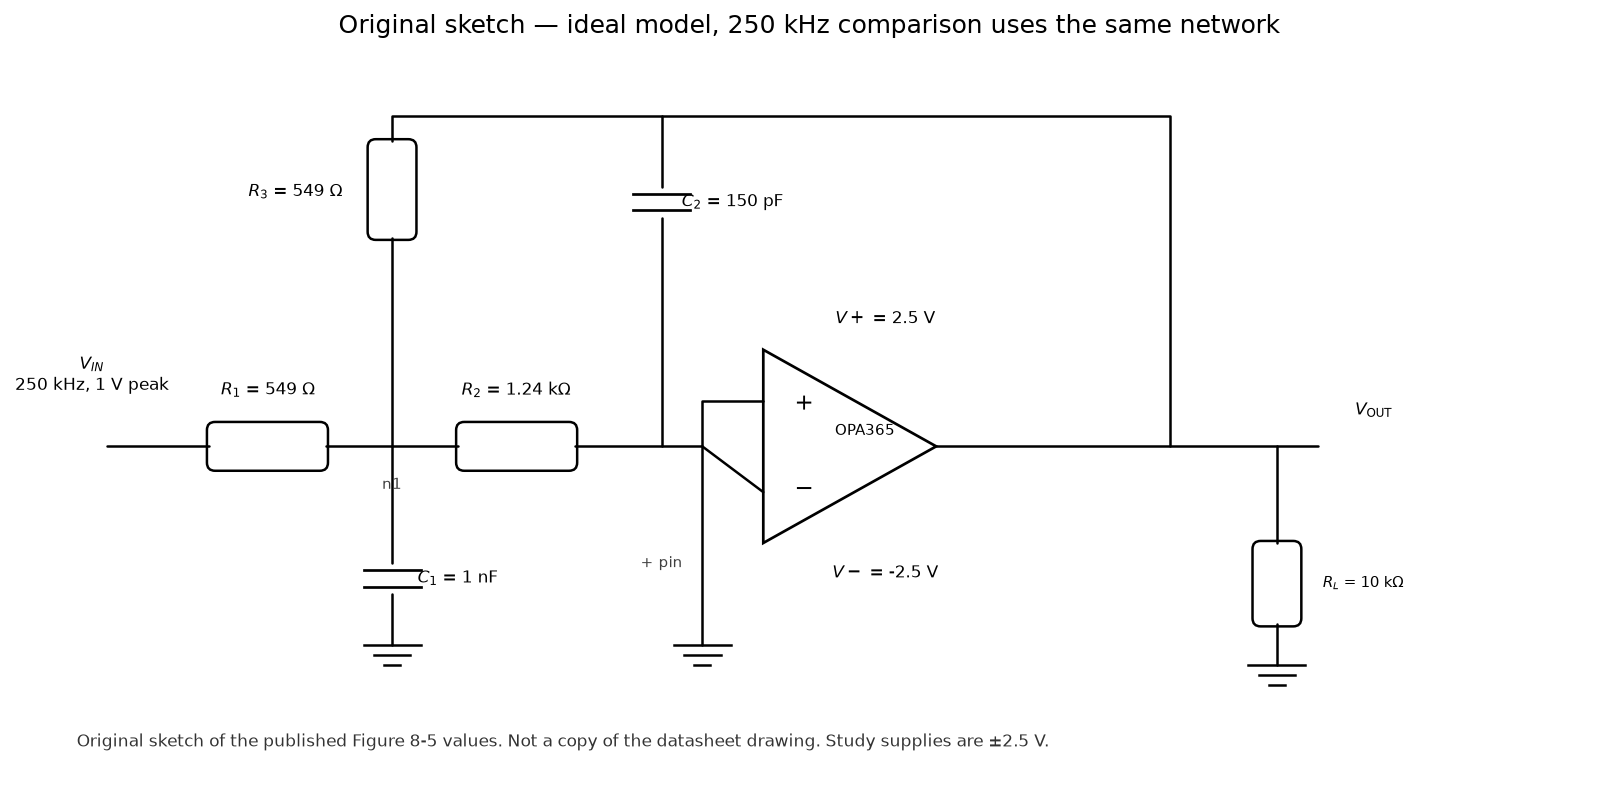

In [3]:
from mfb_design.analysis import bode, find_fc_3db, gain_at, natural_frequency_hz
from mfb_design.schematic import draw_fig85_schematic
from mfb_design.simulate import compare_ac_to_analytical, fc_from_mag, simulate_ac, simulate_tran
from mfb_design.transient import (
    analytical_tone, analytical_waveform, measure_tone, resolve_opa365_lib, waveform_error,
)

draw_fig85_schematic(
    p=p,
    title="Original sketch — ideal model, 250 kHz comparison uses the same network",
    vin_label="$V_{IN}$\n250 kHz, 1 V peak",
)
plt.show()


In [4]:
ac = simulate_ac(p, opamp_model="ideal", workdir=ROOT / "results" / "ngspice" / "nb02_ac", root=ROOT)
h_an = np.array([gain_at(p, float(f)) for f in ac.f_hz])
err = compare_ac_to_analytical(ac, h_an)
lib = resolve_opa365_lib(ROOT)
print("Local macromodel:", "available" if lib else "not found")
ac_m = None
if lib is not None:
    from mfb_design.netlist import NetlistOptions
    ac_m = simulate_ac(
        p,
        opamp_model="opa365",
        workdir=ROOT / "results" / "ngspice" / "nb02_ac_macro",
        root=ROOT,
        opt=NetlistOptions(opamp_model="opa365", analysis="ac", lib_path=lib),
    )
rows = [{
    "model": "ideal",
    "fc_Hz": fc_from_mag(ac.f_hz, np.abs(ac.h)),
    "max_abs_dB": err["max_abs_err_db"],
    "max_abs_phase_deg": err["max_abs_phase_err_deg"],
}]
if ac_m is not None:
    rows.append({
        "model": "macromodel",
        "fc_Hz": fc_from_mag(ac_m.f_hz, np.abs(ac_m.h)),
        "max_abs_dB": np.nan,
        "max_abs_phase_deg": np.nan,
    })
rows.append({
    "model": "analytical",
    "fc_Hz": find_fc_3db(p),
    "max_abs_dB": 0.0,
    "max_abs_phase_deg": 0.0,
})
display(pd.DataFrame(rows))


Local macromodel: available


,model,fc_Hz,max_abs_dB,max_abs_phase_deg
0,ideal,495296.197876,0.000021,0.00005
1,macromodel,492645.096202,NaN,NaN
2,analytical,495372.696835,0.000000,0.00000


Analytical fc = 495372.7 Hz
GBW / (|Hdc| f0) = 100.4


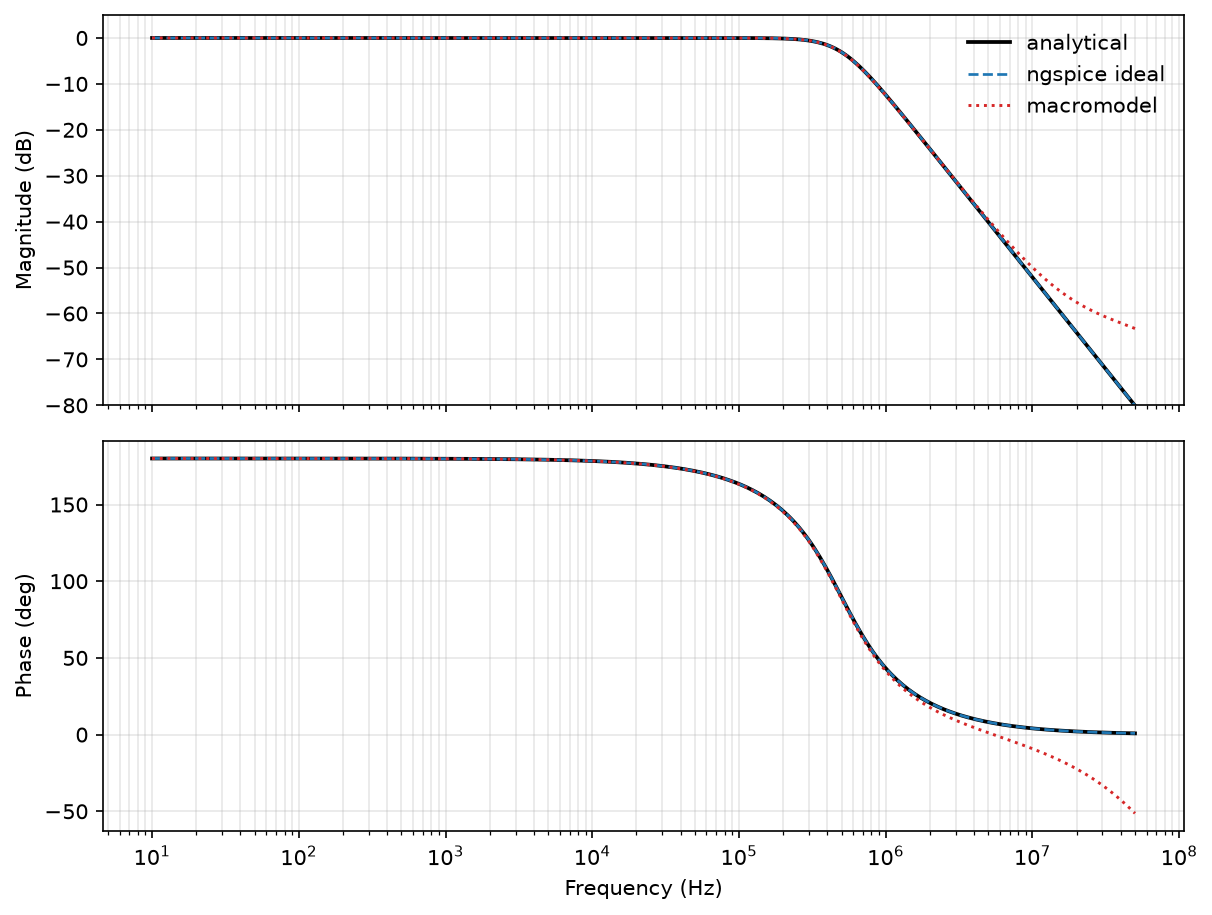

In [5]:
from mfb_design.analysis import find_fc_3db
f = ac.f_hz
fig, axes = plt.subplots(2, 1, figsize=(8.2, 6.2), sharex=True)
axes[0].semilogx(f, 20*np.log10(np.maximum(np.abs(h_an), 1e-30)), "k-", lw=1.8, label="analytical")
axes[0].semilogx(f, ac.mag_db, "C0--", lw=1.3, label="ngspice ideal")
if ac_m is not None:
    axes[0].semilogx(ac_m.f_hz, ac_m.mag_db, "C3:", lw=1.4, label="macromodel")
axes[0].set_ylabel("Magnitude (dB)")
axes[0].set_ylim(-80, 5)
axes[0].grid(True, which="both", alpha=0.3)
axes[0].legend(frameon=False)
axes[1].semilogx(f, np.rad2deg(np.unwrap(np.angle(h_an))), "k-", lw=1.8, label="analytical")
axes[1].semilogx(f, np.rad2deg(np.unwrap(np.angle(ac.h))), "C0--", lw=1.3, label="ngspice ideal")
if ac_m is not None:
    axes[1].semilogx(ac_m.f_hz, ac_m.phase_unwrapped_deg, "C3:", lw=1.4, label="macromodel")
axes[1].set_xlabel("Frequency (Hz)")
axes[1].set_ylabel("Phase (deg)")
axes[1].grid(True, which="both", alpha=0.3)
fig.tight_layout()
print(f"Analytical fc = {find_fc_3db(p):.1f} Hz")
gbw_ratio = p.opamp.gb_w / (abs(p.R3 / p.R1) * natural_frequency_hz(p))
print(f"GBW / (|Hdc| f0) = {gbw_ratio:.1f}")
plt.show()


## 250 kHz transient

The residual is the ngspice sample minus the analytical waveform at that same
time. The analytical solution is integrated onto the simulator's saved time
points. The required output slope at this tone is about 1.5 V/µs. The OPA365
typical slew rate is 25 V/µs.


In [6]:
tr = simulate_tran(
    p, opamp_model="ideal",
    workdir=ROOT / "results" / "ngspice" / "nb02_tran",
    root=ROOT,
)
tone = measure_tone(tr.time, tr.vin, tr.vout)
an = analytical_tone(p)
_, vref = analytical_waveform(p, tr.time)
resid = waveform_error(tr.vout, vref, tr.time)
tr_m = None
tone_m = None
if lib is not None:
    tr_m = simulate_tran(
        p, opamp_model="opa365",
        workdir=ROOT / "results" / "ngspice" / "nb02_tran_macro",
        root=ROOT, lib_path=lib,
    )
    tone_m = measure_tone(tr_m.time, tr_m.vin, tr_m.vout)
rows = [
    {"model": "analytical", **an.as_dict()},
    {"model": "ngspice ideal", **tone.as_dict()},
]
if tone_m is not None:
    rows.append({"model": "macromodel", **tone_m.as_dict()})
display(pd.DataFrame(rows))
print(
    f"Ideal residual max {resid['max_abs_v']*1e6:.1f} µV, "
    f"rms {resid['rms_v']*1e6:.1f} µV, n = {resid['n']}"
)
vout_peak = an.vout_amp
slew = 2 * np.pi * p.op.f_passband_hz * vout_peak
print(f"Output slope at the tone: {slew/1e6:.2f} V/µs. Datasheet typical slew is 25 V/µs.")


,model,gain,phase_deg,vin_amp,vout_amp,vin_dc,vout_dc
0,analytical,0.967223,136.346270,1.0,0.967223,0.000000e+00,0.000000e+00
1,ngspice ideal,0.967181,136.330512,1.0,0.967181,4.548943e-11,-5.444362e-09
2,macromodel,0.967495,135.620237,1.0,0.967495,1.655965e-11,-1.237224e-07


Ideal residual max 269.3 µV, rms 190.4 µV, n = 1001
Output slope at the tone: 1.52 V/µs. Datasheet typical slew is 25 V/µs.


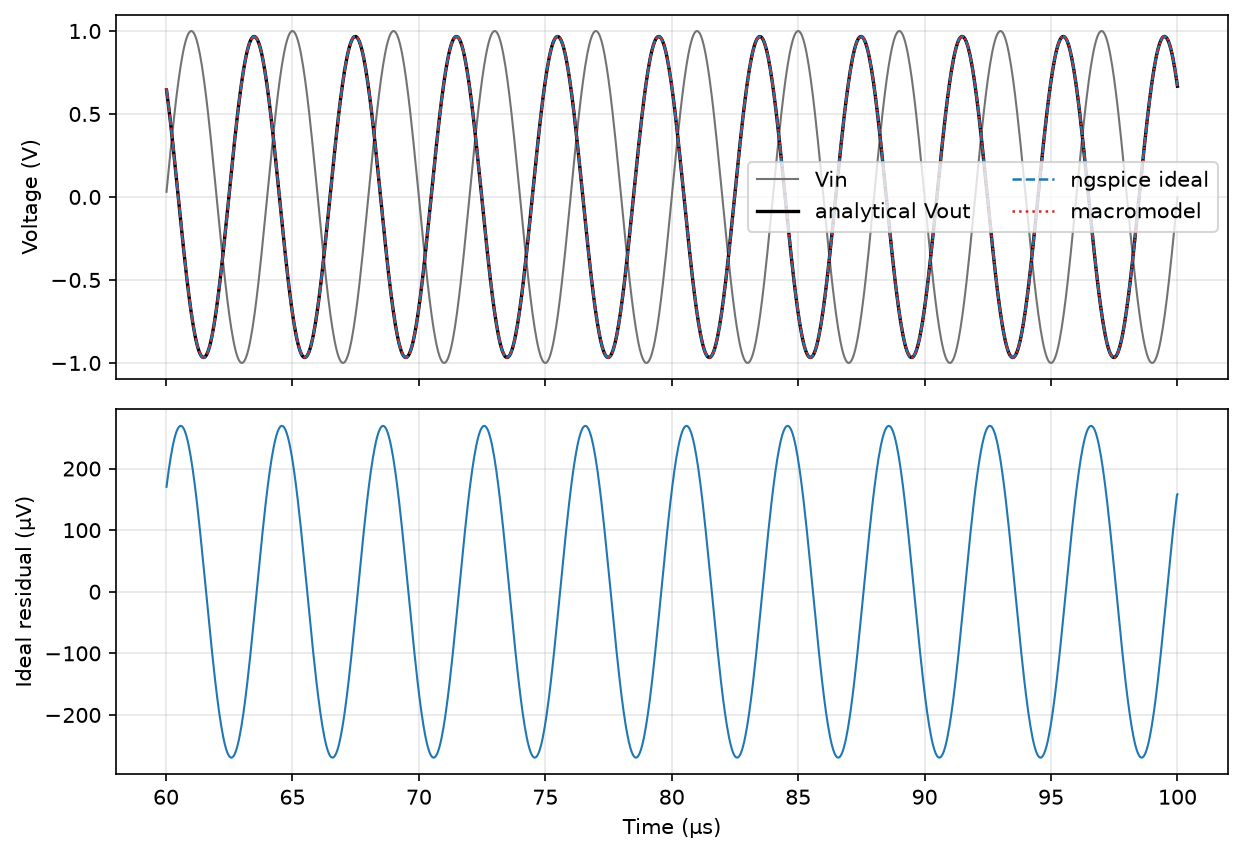

In [8]:
m = tr.time >= 60e-6
fig, axes = plt.subplots(2, 1, figsize=(8.4, 5.8), sharex=True)
axes[0].plot(tr.time[m]*1e6, tr.vin[m], color="0.45", lw=1.0, label="Vin")
axes[0].plot(tr.time[m]*1e6, vref[m], "k-", lw=1.6, label="analytical Vout")
axes[0].plot(tr.time[m]*1e6, tr.vout[m], "C0--", lw=1.2, label="ngspice ideal")
if tr_m is not None:
    mm = tr_m.time >= 60e-6
    axes[0].plot(tr_m.time[mm]*1e6, tr_m.vout[mm], "C3:", lw=1.2, label="macromodel")
axes[0].set_ylabel("Voltage (V)")
axes[0].legend(frameon=True, ncol=2)
axes[0].grid(True, alpha=0.3)
axes[1].plot(tr.time[m]*1e6, (tr.vout[m] - vref[m])*1e6, color="C0", lw=1.0)
axes[1].set_xlabel("Time (µs)")
axes[1].set_ylabel("Ideal residual (µV)")
axes[1].grid(True, alpha=0.3)
fig.tight_layout()
plt.show()
